In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import joblib

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.utils import shuffle
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.utils import plot_model
from tensorflow.keras.optimizers import Adam

RANDOM_KEY=26
TAILLE_IMAGE=(224, 224)

# Parcourir les dossiers et charger les images

In [2]:
def charger_images(chemin_dataset):
    images = []
    labels = []

    extensions_valides = {".jpeg", ".jpg", ".bmp", ".png"}

    for dossier in Path(chemin_dataset).iterdir():

        if not dossier.is_dir():
            continue

        label = dossier.name

        for fichier in dossier.iterdir():

            if fichier.suffix.lower() not in extensions_valides:
                continue

            try:
                image = cv2.imread(str(fichier))

                if image is None:
                    print(f"Image illisible : {fichier}")
                    continue

                image = cv2.resize(image, TAILLE_IMAGE)

                images.append(image)
                labels.append(label)

            except (cv2.error, OSError, ValueError) as erreur:
                print(f"Erreur : {fichier} — {erreur}")

    return images, labels


images, labels = charger_images("/kaggle/input/datasets/hamzahajjaji/dataset-bref-4/Data")

print("Nombre d'images :", len(images))
print("Nombre de labels :", len(labels))

print("Shape de la première image :", images[0].shape)
print("Label de la première image :", labels[0])

Nombre d'images : 7023
Nombre de labels : 7023
Shape de la première image : (224, 224, 3)
Label de la première image : pituitary


# Mélanger les images et les labels (Shuffling)

In [10]:
def melanger_donnees(images, labels):
    return shuffle(images, labels, random_state=RANDOM_KEY)

images, labels = melanger_donnees(images, labels)

print("Nombre d'images :", len(images))
print("Nombre de labels :", len(labels))

print("Labels des 5 premières images :", labels[:5])

Nombre d'images : 7023
Nombre de labels : 7023
Labels des 5 premières images : ['pituitary', 'pituitary', 'meningioma', 'glioma', 'meningioma']


# Convertir les listes en tableaux NumPy

In [11]:
def convertir_numpy(images, labels):
    X = np.array(images)
    y = np.array(labels)

    return X, y


X, y = convertir_numpy(images, labels)

print("Shape de X :", X.shape)
print("Shape de y :", y.shape)

print("Type de X :", type(X))
print("Type de y :", type(y))

print("Premier label :", y[0])

Shape de X : (7023, 224, 224, 3)
Shape de y : (7023,)
Type de X : <class 'numpy.ndarray'>
Type de y : <class 'numpy.ndarray'>
Premier label : pituitary


# Afficher la distribution et l'équilibre des images par classe

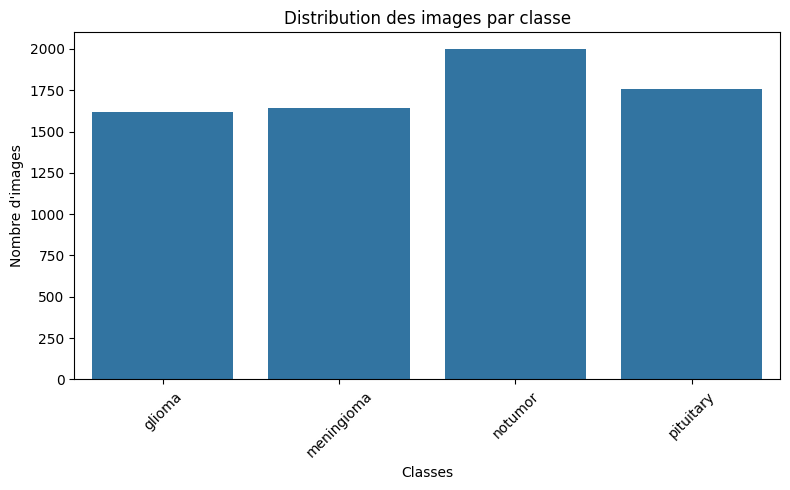

glioma : 1621 images 23.08 %
meningioma : 1645 images 23.42 %
notumor : 2000 images 28.48 %
pituitary : 1757 images 25.02 %


In [12]:
def afficher_distribution(labels):
    classes, nombres = np.unique(labels, return_counts=True)

    plt.figure(figsize=(8, 5))

    sns.barplot(
        x=classes,
        y=nombres
    )

    plt.title("Distribution des images par classe")
    plt.xlabel("Classes")
    plt.ylabel("Nombre d'images")

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    # equilibre
    total = len(labels)
    for c, n in zip(classes, nombres):
        percentage = n / total * 100
        print(f'{c} : {n} images {percentage:.2f} %')

afficher_distribution(y)

# Afficher un échantillon d'images de chaque classe

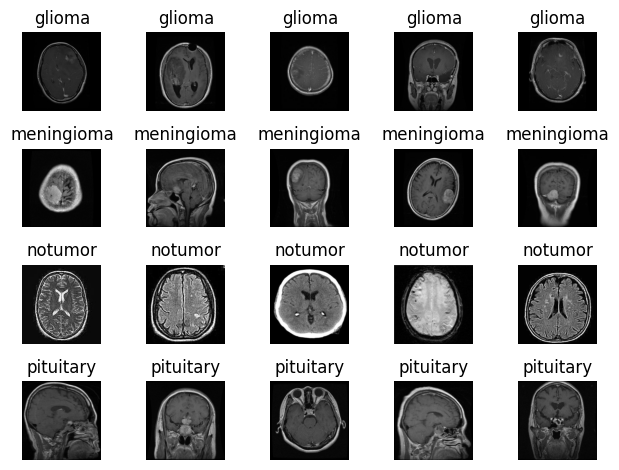

In [13]:
def afficher_exemples(X, y):
    classes = np.unique(y)

    fig, axes = plt.subplots(len(classes), 5)

    for i, classe in enumerate(classes):
        indices = np.where(y == classe)[0][:5]
        # print(indices)

        for j, index in enumerate(indices):
            image = cv2.cvtColor(
                X[index],
                cv2.COLOR_BGR2RGB
            )

            axes[i, j].imshow(image)
            axes[i, j].set_title(str(classe))
            axes[i, j].axis("off")

    plt.tight_layout()
    plt.show()

afficher_exemples(X, y)

# Encoder les labels avec LabelEncoder

In [15]:
def encoder_labels(labels):
    encoder = LabelEncoder()
    y_encoded = encoder.fit_transform(labels)

    # save ecoder
    joblib.dump(
        encoder,
        "label_encoder.pkl"
    )
    
    return y_encoded, encoder

y_encoded, label_encoder = encoder_labels(y)

print("Classes :", label_encoder.classes_)
print("Labels originaux :", y[:5])
print("Labels encodés :", y_encoded[:5])

Classes : ['glioma' 'meningioma' 'notumor' 'pituitary']
Labels originaux : ['pituitary' 'pituitary' 'meningioma' 'glioma' 'meningioma']
Labels encodés : [3 3 1 0 1]


# Normaliser les images

In [7]:
def normaliser_images(X):
    X_normalized = X.astype("float32") / 255
    return X_normalized

X_normalized = normaliser_images(X)

print("Shape :", X_normalized.shape)
print("Type :", X_normalized.dtype)
print("Pixel minimum :", X_normalized.min())
print("Pixel maximum :", X_normalized.max())

Shape : (7023, 224, 224, 3)
Type : float32
Pixel minimum : 0.0
Pixel maximum : 1.0


# Comparer une image avant et après normalisation

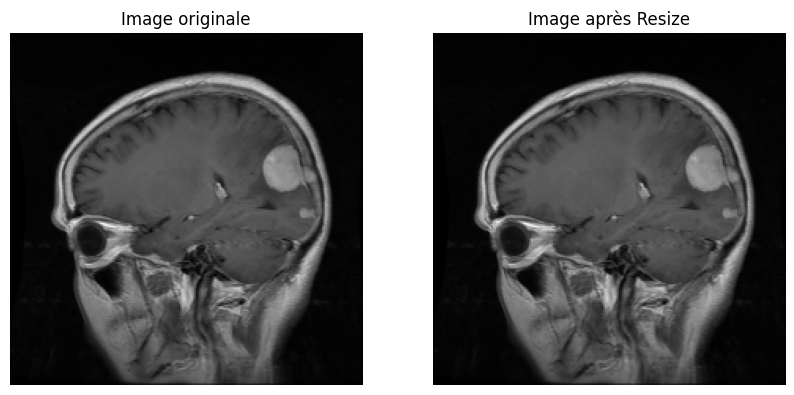

In [8]:
plt.figure(figsize=(10, 5))

image_origin = cv2.cvtColor(X[0], cv2.COLOR_BGR2RGB)
image_normalized = cv2.cvtColor(X_normalized[0], cv2.COLOR_BGR2RGB)

plt.subplot(1, 2, 1)
plt.imshow(image_origin)
plt.title("Image originale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image_normalized)
plt.title("Image après Resize")
plt.axis("off")

plt.show()

# Diviser les données avec train_test_split

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X_normalized,
    y_encoded,
    test_size=0.2,
    random_state=RANDOM_KEY,
    stratify=y_encoded
)

print("X_train :", X_train.shape)
print("y_train :", y_train.shape)

print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

NameError: name 'y_encoded' is not defined

# Créer les données Validation

In [64]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=RANDOM_KEY,
    stratify=y_train
)

print("X_train :", X_train.shape)
print("y_train :", y_train.shape)

print("X_val :", X_val.shape)
print("y_val :", y_val.shape)

print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

X_train : (4494, 224, 224, 3)
y_train : (4494,)
X_val : (1124, 224, 224, 3)
y_val : (1124,)
X_test : (1405, 224, 224, 3)
y_test : (1405,)


# One-Hot Encoding

In [65]:
y_train = to_categorical(y_train, num_classes=4)
y_val = to_categorical(y_val, num_classes=4)
y_test = to_categorical(y_test, num_classes=4)

# Architecture du CNN

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_4 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,177,476 (42.64 MB)

 Trainable params: 11,177,476 (42.64 MB)

 Non-trainable params: 0 (0.00 B)

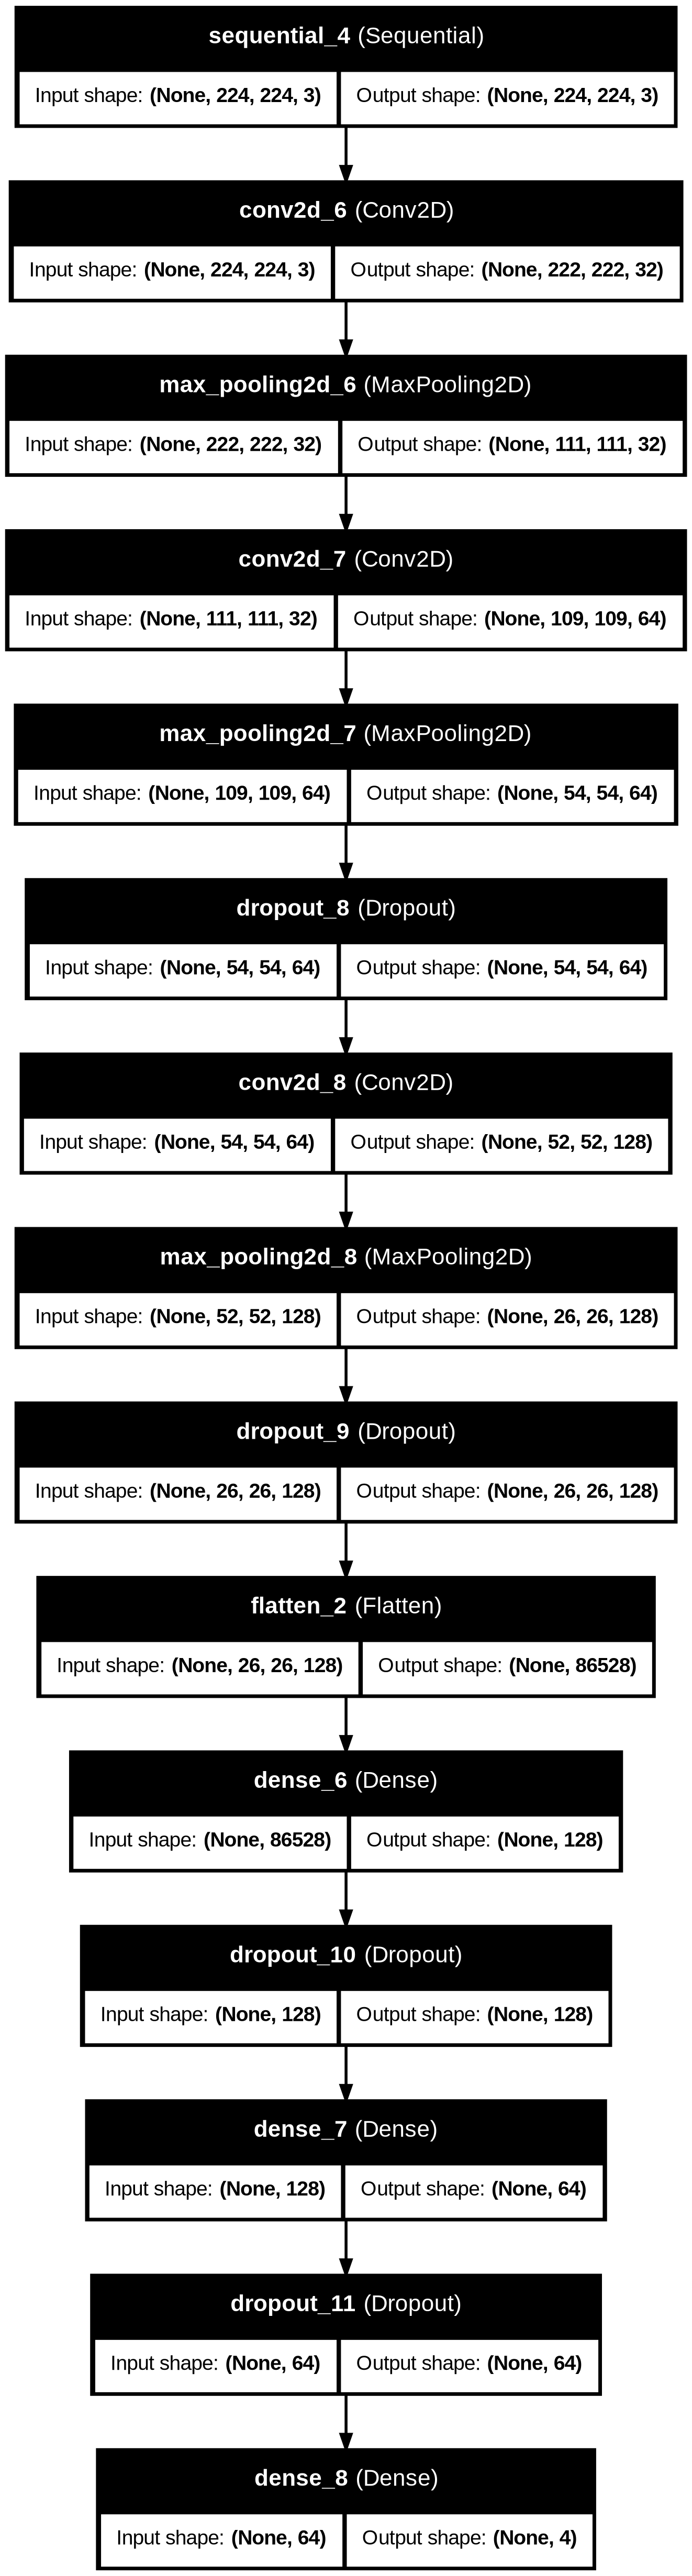

In [66]:
def creer_modele_cnn():
    # Data Augmentation
    data_augmentation = tf.keras.Sequential([
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.1),
    ])
    
    model = models.Sequential([
        # Layer Inpute
        layers.Input(shape=(224, 224, 3)),
        
        # Appliquer une augmentation
        data_augmentation,

        # Convolaton layer 1
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        # Convolaton layer 2
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # Convolaton layer 3
        layers.Conv2D(128, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # Flatten
        layers.Flatten(),

        # Hidden layers
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),

        layers.Dense(64, activation="relu"),
        layers.Dropout(0.5),

        # Classification
        layers.Dense(4, activation="softmax")
    ])
    
    return model

model = creer_modele_cnn()

# Architecture avec summary et plot_model
model.summary()

plot_model(
    model,
    show_shapes=True,
    show_layer_names=True
)

# Compiler le modèle avec compile()

In [67]:
def compiler_modele(model):
    # taux d'apprentissage
    optimizer = Adam(learning_rate=0.001)

    model.compile(
        optimizer=optimizer,
        loss="categorical_crossentropy", # parce que les class dans y represent avec One-Hot
        metrics=["accuracy"]
    )
    return model

model = compiler_modele(model)

# Les Callbacks

In [68]:
# Folder pour sauvgarder model
Path("checkpoints").mkdir(parents=True, exist_ok=True)

# Callbacks
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath="meilleur_modele.keras",
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.BackupAndRestore(
        backup_dir="backup_training"
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    )
]

# Entraîner le modèle avec fit()

In [69]:
def entrainer_modele(model, X_train, y_train, X_val, y_val, callbacks):
    start_time = time.time()
    
    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=20,
        batch_size=32,
        callbacks=callbacks
    )

    end_time = time.time()
    duree = end_time - start_time

    print(f"Durée d'entraînement : {duree:.2f} secondes")
    print(f"Durée d'entraînement : {duree / 60:.2f} minutes")
    
    return history

history = entrainer_modele(
    model,
    X_train,
    y_train,
    X_val,
    y_val,
    callbacks
)

print(history.history.keys())

Epoch 1/20


E0000 00:00:1792404046.004234      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/sequential_5_1/dropout_8_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


140/141 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.3557 - loss: 1.3505
Epoch 1: val_loss improved from None to 0.87939, saving model to meilleur_modele.keras

Epoch 1: finished saving model to meilleur_modele.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - accuracy: 0.4502 - loss: 1.2042 - val_accuracy: 0.6815 - val_loss: 0.8794
Epoch 2/20
140/141 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.6244 - loss: 0.9262
Epoch 2: val_loss improved from 0.87939 to 0.54263, saving model to meilleur_modele.keras

Epoch 2: finished saving model to meilleur_modele.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 13s 93ms/step - accuracy: 0.6513 - loss: 0.8491 - val_accuracy: 0.7776 - val_loss: 0.5426
Epoch 3/20
140/141 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.7035 - loss: 0.6946
Epoch 3: val_loss improved from 0.54263 to 0.50312, saving model to meilleur_modele.keras

Epoch 3: finished saving model to meilleur_modele.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 13s 93ms/step - accuracy: 0.7138 - loss: 0.6

# Visualiser l’apprentissage avec history

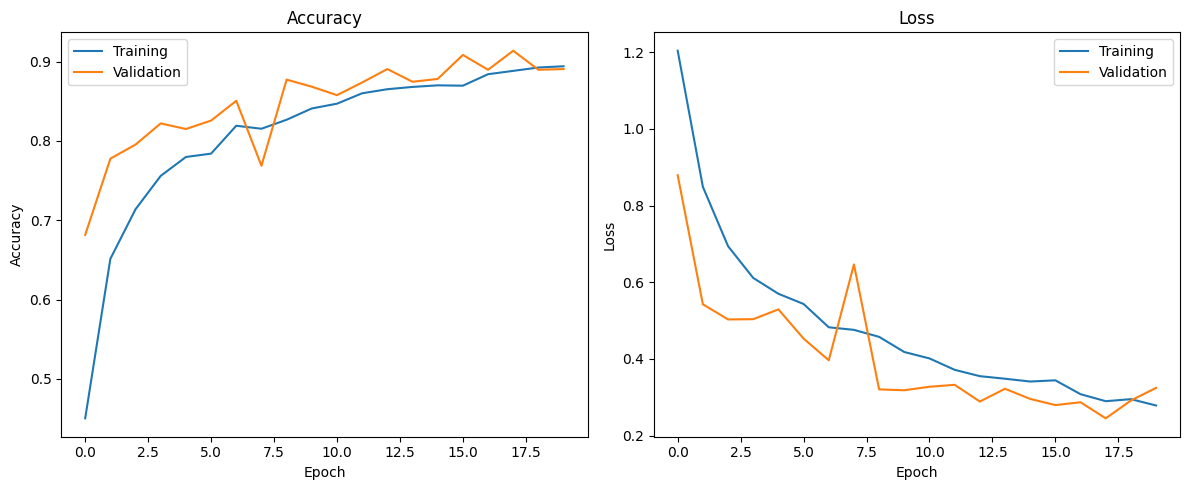

In [70]:
def afficher_courbes(history):
    plt.figure(figsize=(12, 5))

    # Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(history.history["accuracy"], label="Training")
    plt.plot(history.history["val_accuracy"], label="Validation")
    plt.title("Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    # Loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history["loss"], label="Training")
    plt.plot(history.history["val_loss"], label="Validation")
    plt.title("Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()

afficher_courbes(history)

# Évaluer le modèle avec X_test

In [71]:
def evaluer_modele(model, X_test, y_test):
    loss, accuracy = model.evaluate(
        X_test,
        y_test,
        verbose=1
    )

    print(f"Test Loss : {loss:.4f}")
    print(f"Test Accuracy : {accuracy:.4f}")

    return loss, accuracy

test_loss, test_accuracy = evaluer_modele(
    model,
    X_test,
    y_test
)

44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9096 - loss: 0.2188
Test Loss : 0.2188
Test Accuracy : 0.9096


# Prédire les classes avec model.predict()

In [72]:
def predire_classes(model, X_test, label_encoder):
    y_prob = model.predict(X_test)

    y_pred = np.argmax(y_prob, axis=1)

    classes_predites = label_encoder.inverse_transform(y_pred)

    return y_prob, y_pred, classes_predites

y_prob, y_pred, classes_predites = predire_classes(
    model,
    X_test,
    label_encoder
)

print("Probabilités :", y_prob[0])
print("Classe prédite :", classes_predites[0])

44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step
Probabilités : [3.3825075e-13 2.1707169e-06 9.9999785e-01 1.3980843e-13]
Classe prédite : notumor


# Évaluer les prédictions avec la Confusion Matrix

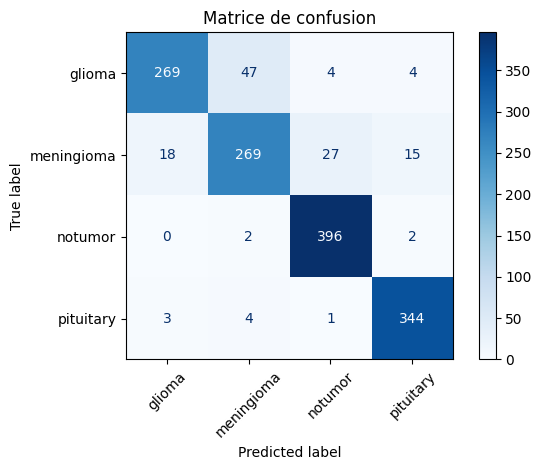

In [74]:
def afficher_matrice_confusion(y_test, y_pred, label_encoder):

    # Si y_test est en One-Hot Encoding
    if y_test.ndim == 2:
        y_test = np.argmax(y_test, axis=1)

    classes = label_encoder.classes_

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=np.arange(len(classes))
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=classes
    )

    display.plot(cmap="Blues", xticks_rotation=45)
    plt.title("Matrice de confusion")
    plt.tight_layout()
    plt.show()

    return cm

cm = afficher_matrice_confusion(
    y_test,
    y_pred,
    label_encoder
)

# Calculer les métriques : Precision, Recall et F1-score

In [77]:
def evaluer_metriques(y_test, y_pred, label_encoder):
    # Convertir y_test de One-Hot vers labels numériques
    if y_test.ndim == 2:
        y_test = np.argmax(y_test, axis=1)

    rapport = classification_report(
        y_test,
        y_pred,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    )

    print(rapport)
    return rapport


rapport = evaluer_metriques(
    y_test,
    y_pred,
    label_encoder
)

              precision    recall  f1-score   support

      glioma       0.93      0.83      0.88       324
  meningioma       0.84      0.82      0.83       329
     notumor       0.93      0.99      0.96       400
   pituitary       0.94      0.98      0.96       352

    accuracy                           0.91      1405
   macro avg       0.91      0.90      0.90      1405
weighted avg       0.91      0.91      0.91      1405



# Visualiser les erreurs de classification

Images bien classées : 1278
Images mal classées : 127


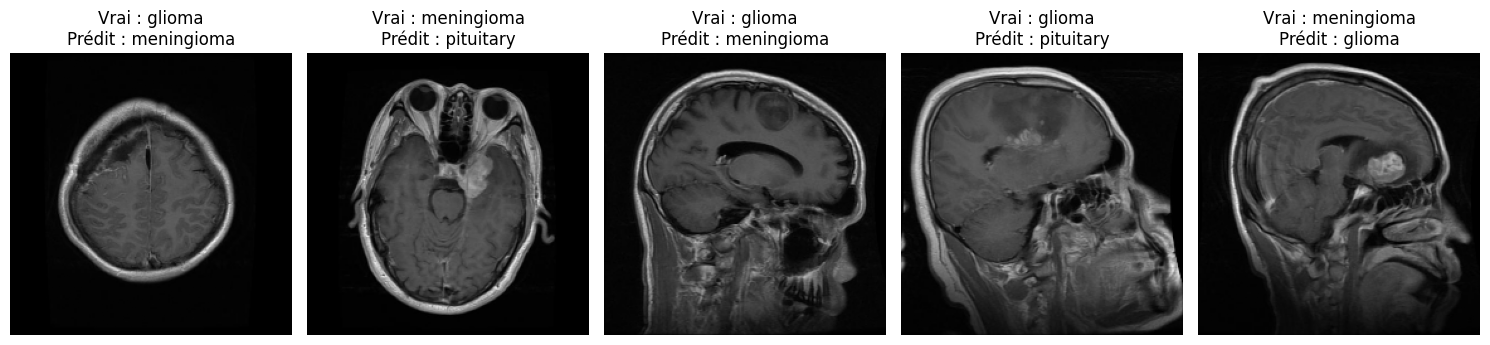

In [79]:

# Convertir y_test One-Hot vers labels numériques
y_test_labels = np.argmax(y_test, axis=1)

# Comparer les vraies classes avec les prédictions
correct_indices = np.where(y_test_labels == y_pred)[0]
wrong_indices = np.where(y_test_labels != y_pred)[0]

print("Images bien classées :", len(correct_indices))
print("Images mal classées :", len(wrong_indices))

n = min(5, len(wrong_indices))

if n > 0:
    plt.figure(figsize=(15, 4))

    for i in range(n):
        idx = wrong_indices[i]

        plt.subplot(1, n, i + 1)
        plt.imshow(X_test[idx])

        true_label = label_encoder.inverse_transform(
            [y_test_labels[idx]]
        )[0]

        predicted_label = label_encoder.inverse_transform(
            [y_pred[idx]]
        )[0]

        plt.title(
            f"Vrai : {true_label}\nPrédit : {predicted_label}"
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Aucune image mal classée.")

# Créer une fonction predict_image()

In [80]:
def predict_image(image_path):
    image_path = Path(image_path)

    # 1. Vérifier le fichier
    if not image_path.is_file():
        raise FileNotFoundError(
            f"Image introuvable : {image_path}"
        )

    # 2. Vérifier l'extension
    extensions = {".jpg", ".jpeg", ".png", ".bmp"}

    if image_path.suffix.lower() not in extensions:
        raise ValueError("Format d'image non autorisé.")

    # 3. Lire l'image
    image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)

    if image is None:
        raise ValueError("Impossible de lire cette image.")

    # 4. BGR vers RGB
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # 5. Resize
    image = cv2.resize(image, (224, 224))

    # 6. Normalisation
    image = image.astype("float32") / 255.0

    # 7. Ajouter la dimension du batch
    image = np.expand_dims(image, axis=0)

    # 8. Prédiction
    probabilities = model.predict(image, verbose=0)[0]

    predicted_index = np.argmax(probabilities)

    predicted_class = label_encoder.inverse_transform(
        [predicted_index]
    )[0]

    confidence = float(probabilities[predicted_index])

    return predicted_class, confidence, probabilities


classe, confiance, probabilites = predict_image('/kaggle/input/datasets/hamzahajjaji/dataset-bref-4/Data/glioma/Te-glTr_0000.jpg')

print("Classe prédite :", classe)
print(f"Confiance du modèle : {confiance:.2%}")
print("Probabilités :", probabilites)

Classe prédite : glioma
Confiance du modèle : 52.75%
Probabilités : [0.5274865  0.15700671 0.20127958 0.11422719]
